# Trip EDA (Ride or Rail?)
This notebook looks at basic patterns in Chicago rideshare trips: when people ride, where they start, how far they go, and how much they pay. Right now it runs on a 200,000-trip sample from early 2025. We will rerun it on the full dataset (2018 to 2026).

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


In [3]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA = "tnp_sample"   # change to "tnp" when the full conversion is done

spark = (SparkSession.builder.appName("trip-eda")
         .config("spark.driver.memory", "1g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

df = spark.read.parquet(str(ROOT / "data" / "parquet" / DATA))

for c in ["trip_seconds", "trip_miles", "fare"]:
    df = df.withColumn(c, F.col(c).cast("double"))
df = df.withColumn("pickup_area", F.col("pickup_community_area").cast("int"))

# cleaning rules from the data-quality notebook
df = df.filter((F.col("trip_seconds") > 0) & (F.col("trip_miles") > 0)
               & (F.col("trip_seconds") <= 4 * 3600) & (F.col("trip_miles") <= 100))

df = df.withColumn("hour", F.hour("trip_start_timestamp")) \
       .withColumn("dow", F.dayofweek("trip_start_timestamp"))   # 1 = Sunday

print(df.count())


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/28 22:14:47 WARN Utils: Your hostname, Dharmiks-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 10.0.0.246 instead (on interface en0)
26/10/28 22:14:47 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/28 22:14:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


199878


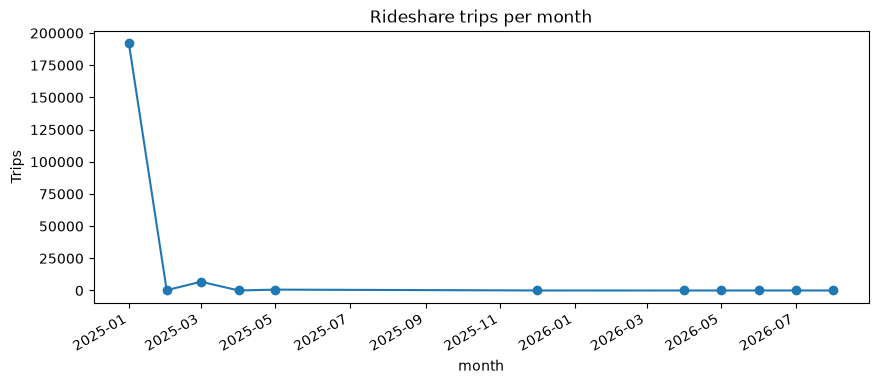

In [4]:
m = df.groupBy(F.date_trunc("month", "trip_start_timestamp").alias("month")).count() \
      .orderBy("month").toPandas()
m.plot(x="month", y="count", figsize=(10, 4), legend=False, marker="o",
       title="Rideshare trips per month")
plt.ylabel("Trips"); plt.show()

Almost all trips in the sample are from January 2025, because the sample is just the first rows of the 2025 file. This chart is not useful yet. On the full data it will show how rideshare use changed over the years, including the drop during COVID in 2020.

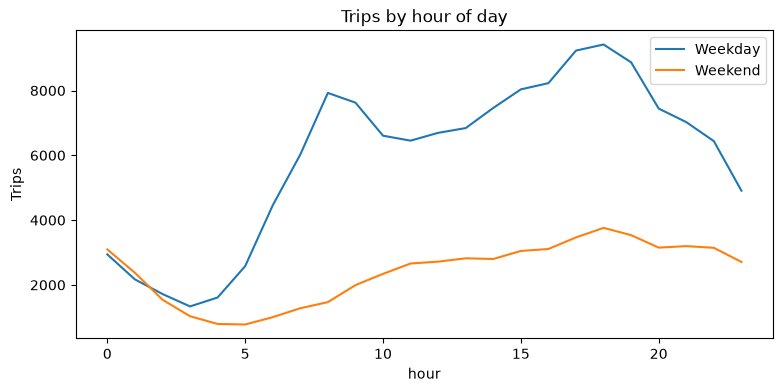

In [5]:
h = df.withColumn("weekend", F.col("dow").isin(1, 7)) \
      .groupBy("hour", "weekend").count().toPandas() \
      .pivot(index="hour", columns="weekend", values="count").sort_index()
h.columns = ["Weekday" if not c else "Weekend" for c in h.columns]
h.plot(figsize=(9, 4), title="Trips by hour of day")
plt.ylabel("Trips"); plt.show()

On weekdays there are two busy times: a morning peak around 8 am and a bigger evening peak around 5 to 6 pm. This matches people going to and from work. Weekends are flatter, start later in the morning, and stay busier late at night. Late at night (around midnight to 1 am), weekends are about as busy as weekdays.

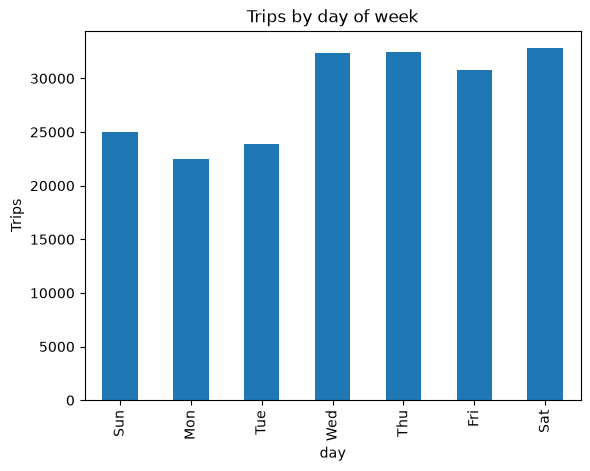

In [6]:
d = df.groupBy("dow").count().orderBy("dow").toPandas()
d["day"] = d["dow"].map({1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"})
d.plot(kind="bar", x="day", y="count", legend=False, title="Trips by day of week")
plt.ylabel("Trips"); plt.show()

Wednesday, Thursday, Friday and Saturday have the most trips, and Sunday to Tuesday have fewer. Part of this is because January 2025 had five Wednesdays, Thursdays and Fridays but only four of the other days. The full data will give a fairer comparison.

In [7]:
FRAC = 0.2 if DATA == "tnp_sample" else 0.01   # use more of the sample, less of the full data

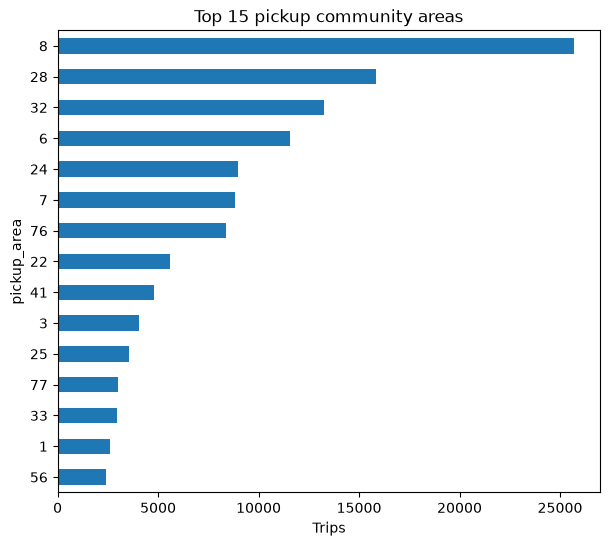

In [8]:
a = df.filter(F.col("pickup_area").isNotNull()).groupBy("pickup_area").count() \
      .orderBy(F.desc("count")).limit(15).toPandas()
a["pickup_area"] = a["pickup_area"].astype(str)
a.plot(kind="barh", x="pickup_area", y="count", legend=False, figsize=(7, 6),
       title="Top 15 pickup community areas")
plt.xlabel("Trips"); plt.gca().invert_yaxis(); plt.show()


Most trips start in a few central areas. The busiest pickup area is 8 (Near North Side), followed by 28 (Near West Side) and 32 (Loop). The airports also appear: O'Hare (76) is 7th and Midway (56) is 15th. Trips are concentrated downtown, which is also where CTA service is strongest.

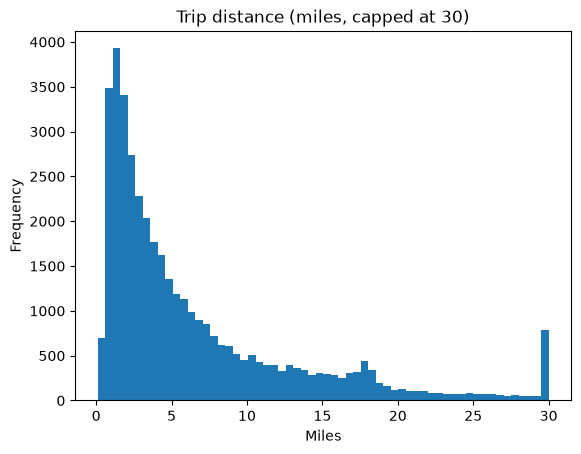

In [9]:
dist = df.select(F.least(F.col("trip_miles"), F.lit(30)).alias("miles")) \
         .sample(FRAC, seed=1).toPandas()
dist["miles"].plot(kind="hist", bins=60, title="Trip distance (miles, capped at 30)")
plt.xlabel("Miles"); plt.show()

Most trips are short: the most common distance is 1 to 2 miles, and most trips are under about 5 miles. The number of trips drops quickly as distance increases. There is a small bump around 17 to 18 miles, which is about the distance from downtown to O'Hare, so these are likely airport trips. The spike at 30 is because all trips of 30 miles or more were grouped into the last bar.

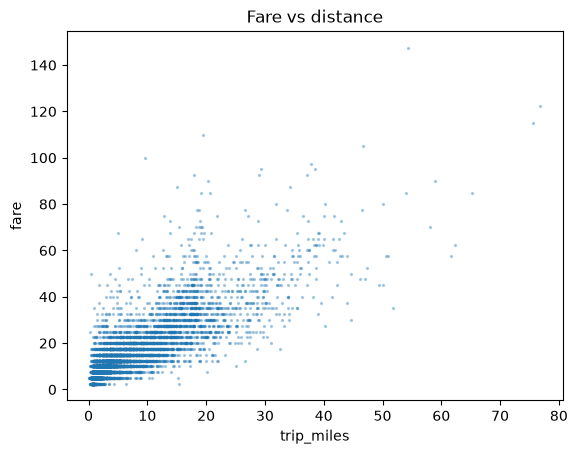

In [10]:
fd = df.filter(F.col("fare") > 0).select("trip_miles", "fare") \
       .sample(FRAC / 5, seed=1).toPandas()
fd.plot(kind="scatter", x="trip_miles", y="fare", s=2, alpha=0.3,
        title="Fare vs distance")
plt.show()

Longer trips cost more, so fare goes up with distance. Most trips are under 20 miles and under $50. There is a lot of spread at the same distance, likely because of surge pricing and traffic. The fares look like horizontal lines because the city rounds fares to the nearest $2.50 to protect privacy. A few trips over 70 miles cost more than $200.